# 02 (v2) — Baza modellər, Excel pozuntuları çıxarılmış dataset

`02_baseline_models.ipynb`-in eyni məntiqi, iki fərqlə:
- Dataset: `clean.csv`-dən Excel pozuntuları (elmi format, `#NAME?`, yalnız `\d+%`) çıxarılır → `clean_v2.csv`.
- **Əsas model Logistic Regression-dur** (ehtimal çıxışı verir — middleware-də hədd tənzimlənir).
  Linear SVM, RF və NB müqayisə üçün saxlanılır; dörd modelin hamısı 03 notebook-u üçün `models/`-ə yazılır.

v1 nəticələri (`results/baseline_results.csv`) dəyişdirilmir; bu notebook-un bütün çıxışları `_v2` şəkilçisi daşıyır.
Seed = 42.

## 0. Mühit və yollar

In [1]:
import random
import re
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.svm import LinearSVC

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "figures"
RES_DIR = ROOT / "results"
MODEL_DIR = ROOT / "models"
for d in (FIG_DIR, RES_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

COLORS = {0: "#2a78d6", 1: "#eb6834"}
NAMES = {0: "Təmiz (0)", 1: "Zərərli (1)"}
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e5e4e0",
    "grid.linewidth": 0.6,
    "axes.axisbelow": True,
    "axes.edgecolor": "#8a8984",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
})

def save_fig(fig, name):
    fig.savefig(FIG_DIR / name, dpi=300, bbox_inches="tight")

V = "_v2"
df = pd.read_csv(PROC_DIR / "clean.csv", keep_default_na=False, dtype={"Query": str, "Label": int})
print(df.shape)

(30902, 2)


## 1. Excel pozuntularının çıxarılması → `clean_v2.csv`
Çıxarılan formalar (bütün sorğu bu formaya uyğun gəlməlidir — `LIKE '%` kimi həqiqi hücumlara toxunulmur):
- elmi format: `1.94E+15`
- Excel xətası: `#NAME?` (v1 təmizləməsində ziddiyyətli label kimi artıq silinib, burada təhlükəsizlik üçün yoxlanılır)
- yalnız rəqəm + faiz: `28%`

In [2]:
SCI_RE = r"^\s*[-+]?\d+(\.\d+)?[eE][-+]?\d+\s*$"
NAME_RE = r"^\s*#NAME\?\s*$"
PCT_RE = r"^\s*\d+(\.\d+)?%\s*$"

kinds = {
    "scientific_notation": df["Query"].str.match(SCI_RE),
    "excel_name_error": df["Query"].str.match(NAME_RE),
    "number_percent": df["Query"].str.match(PCT_RE),
}
removed = pd.DataFrame([
    {"artifact": k, "benign_0": int((m & (df.Label == 0)).sum()),
     "malicious_1": int((m & (df.Label == 1)).sum()), "total": int(m.sum())}
    for k, m in kinds.items()
])
removed.to_csv(RES_DIR / "02_v2_removed_artifacts.csv", index=False)
display(removed)

mask = kinds["scientific_notation"] | kinds["excel_name_error"] | kinds["number_percent"]
print("Çıxarılan nümunələr:", df.loc[mask, "Query"].sample(10, random_state=SEED).tolist())
df = df[~mask].reset_index(drop=True)
df[["Query", "Label"]].to_csv(PROC_DIR / "clean_v2.csv", index=False, encoding="utf-8")
print(f"clean_v2.csv: {len(df)} sətir (çıxarılıb: {int(mask.sum())})")
print(df["Label"].value_counts().sort_index().rename(index=NAMES).to_string())

,artifact,benign_0,malicious_1,total
0,scientific_notation,642,1,643
1,excel_name_error,0,0,0
2,number_percent,0,4,4


Çıxarılan nümunələr: ['5.41816E+15', '2.51064E+15', '4.59244E+15', '4.61189E+15', '1.20958E+14', '8.99357E+15', '3.60204E+15', '6.4255E+15', '5.91692E+15', '9.51518E+15']
clean_v2.csv: 30255 sətir (çıxarılıb: 647)
Label
Təmiz (0)      18885
Zərərli (1)    11370


## 2. Qrup əsaslı bölgü
Sorğuları normallaşdırırıq (kiçik hərf, ardıcıl boşluqlar bir boşluğa, kənar boşluqlar silinir) və hər
normallaşdırılmış forma üçün qrup ID veririk. `GroupShuffleSplit` əvvəlcə 70% / 30%, sonra qalan 30%-i
50/50 bölür — nəticədə 70/15/15. Bölgü qruplar üzrə aparıldığı üçün sətir sayları dəqiq 70/15/15 olmaya bilər.
Sonda heç bir qrupun iki dəstdə olmadığını `assert` ilə yoxlayırıq.

In [3]:
def normalize(q):
    return re.sub(r"\s+", " ", q.lower()).strip()

df["norm"] = df["Query"].map(normalize)
df["group_id"] = pd.factorize(df["norm"])[0]
print(f"Sətir: {len(df)}, unikal qrup: {df.group_id.nunique()}, "
      f"birdən çox sətri olan qrup: {(df.group_id.value_counts() > 1).sum()}")

gss1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)
train_idx, rest_idx = next(gss1.split(df, df.Label, df.group_id))
rest = df.iloc[rest_idx]
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
val_idx, test_idx = next(gss2.split(rest, rest.Label, rest.group_id))

train = df.iloc[train_idx].reset_index(drop=True)
val = rest.iloc[val_idx].reset_index(drop=True)
test = rest.iloc[test_idx].reset_index(drop=True)

g = {name: set(part.group_id) for name, part in (("train", train), ("val", val), ("test", test))}
assert not (g["train"] & g["val"]) and not (g["train"] & g["test"]) and not (g["val"] & g["test"])
print("Qrup kəsişməsi yoxdur ✓")

for name, part in (("train", train), ("val", val), ("test", test)):
    part[["Query", "Label", "group_id"]].to_csv(PROC_DIR / f"{name}{V}.csv", index=False, encoding="utf-8")

split_balance = pd.DataFrame([
    {"split": name, "rows": len(part), "share_pct": round(len(part) / len(df) * 100, 2),
     "benign_0": int((part.Label == 0).sum()), "malicious_1": int((part.Label == 1).sum()),
     "malicious_pct": round(part.Label.mean() * 100, 2)}
    for name, part in (("train", train), ("val", val), ("test", test))
]).set_index("split")
split_balance.to_csv(RES_DIR / "02_v2_split_balance.csv")
display(split_balance)

Sətir: 30255, unikal qrup: 30167, birdən çox sətri olan qrup: 84
Qrup kəsişməsi yoxdur ✓


,rows,share_pct,benign_0,malicious_1,malicious_pct
split,,,,,
train,21181,70.01,13228,7953,37.55
val,4535,14.99,2863,1672,36.87
test,4539,15.00,2794,1745,38.44


## 3. Baza modellər: simvol səviyyəli TF-IDF
TF-IDF yalnız **train** dəstində öyrədilir (val/test lüğətə sızmasın). Simvol n-gram 1–5, `sublinear_tf`,
`min_df=2` (yalnız bir dəfə görünən n-gram-lar atılır). Hər model üçün kiçik hiperparametr şəbəkəsi
validation F1-ə görə seçilir; test dəsti bu mərhələdə istifadə olunmur.

In [4]:
X_train, y_train = train["Query"], train["Label"].to_numpy()
X_val, y_val = val["Query"], val["Label"].to_numpy()
X_test, y_test = test["Query"], test["Label"].to_numpy()

vectorizer = TfidfVectorizer(analyzer="char", ngram_range=(1, 5), lowercase=True,
                             sublinear_tf=True, min_df=2, dtype=np.float32)
t0 = time.perf_counter()
Xtr = vectorizer.fit_transform(X_train)
Xva = vectorizer.transform(X_val)
print(f"TF-IDF lüğəti: {len(vectorizer.vocabulary_):,} n-gram, {time.perf_counter() - t0:.1f} s")

GRID = {
    "Logistic Regression": (lambda p: LogisticRegression(C=p, max_iter=2000, random_state=SEED),
                            [0.1, 1, 10, 100]),
    "Linear SVM": (lambda p: LinearSVC(C=p, random_state=SEED), [0.01, 0.1, 1, 10]),
    "Random Forest": (lambda p: RandomForestClassifier(n_estimators=p[0], min_samples_leaf=p[1],
                                                       n_jobs=-1, random_state=SEED),
                      [(200, 1), (200, 2), (400, 1)]),
    "Multinomial NB": (lambda p: MultinomialNB(alpha=p), [0.001, 0.01, 0.1, 1.0]),
}

search_rows, best_params = [], {}
for name, (make, params) in GRID.items():
    best = (-1, None)
    for p in params:
        clf = make(p).fit(Xtr, y_train)
        f1 = f1_score(y_val, clf.predict(Xva))
        search_rows.append({"model": name, "param": str(p), "val_f1": round(f1, 5)})
        if f1 > best[0]:
            best = (f1, p)
    best_params[name] = best[1]
    print(f"{name:20s} ən yaxşı param = {best[1]!s:10s} val F1 = {best[0]:.4f}")

pd.DataFrame(search_rows).to_csv(RES_DIR / "02_v2_val_search.csv", index=False)

TF-IDF lüğəti: 91,121 n-gram, 5.4 s


Logistic Regression  ən yaxşı param = 100        val F1 = 0.9955


Linear SVM           ən yaxşı param = 1          val F1 = 0.9961


Random Forest        ən yaxşı param = (200, 1)   val F1 = 0.9967


Multinomial NB       ən yaxşı param = 0.001      val F1 = 0.9319


Seçilmiş parametrlərlə hər modeli **train** üzərində yenidən öyrədib, vektorlaşdırıcı ilə birlikdə tam
pipeline kimi saxlayırıq (xam sorğu → ehtimal). Metrikalar:

- accuracy, precision, recall, F1 (müsbət sinif = zərərli)
- ROC-AUC (`predict_proba` və ya Linear SVM üçün `decision_function`)
- FPR = FP / (FP + TN) — təmiz sorğuların neçə faizi səhvən bloklanır
- gecikmə: test dəstindən 1000 sorğu **bir-bir** pipeline-dan keçirilir (vektorlaşdırma + proqnoz),
  orta vaxt ms ilə — middleware ssenarisinə ən yaxın ölçü. Əvvəlcə 50 sorğu ilə "isinmə" edilir.
  RF öyrədildikdən sonra `n_jobs=1`-ə keçirilir: v1-də ölçülən 50 ms əsasən tək sorğu üçün thread pool-un
  işə salınma xərci idi, middleware-də isə hər sorğu ayrıca gəlir.

In [5]:
def score(model, X):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)

def latency_ms(model, queries, n=1000, warmup=50):
    qs = queries.sample(n=min(n, len(queries)), random_state=SEED).tolist()
    for q in qs[:warmup]:
        model.predict([q])
    t0 = time.perf_counter()
    for q in qs:
        model.predict([q])
    return (time.perf_counter() - t0) / len(qs) * 1000

def evaluate(name, model, X, y, extra=None):
    pred = model.predict(X)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    row = {
        "model": name,
        "accuracy": accuracy_score(y, pred),
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred),
        "f1": f1_score(y, pred),
        "roc_auc": roc_auc_score(y, score(model, X)),
        "fpr": fp / (fp + tn),
        "tp": tp, "fp": fp, "tn": tn, "fn": fn,
        "latency_ms": latency_ms(model, X),
    }
    row.update(extra or {})
    return row

pipelines, results = {}, []
for name, (make, _) in GRID.items():
    pipe = Pipeline([("tfidf", vectorizer), ("clf", make(best_params[name]))])
    pipe.named_steps["clf"].fit(Xtr, y_train)  # vektorlaşdırıcı artıq train-də öyrədilib
    if name == "Random Forest":
        pipe.named_steps["clf"].set_params(n_jobs=1)
    pipelines[name] = pipe
    val_f1 = f1_score(y_val, pipe.predict(X_val))
    results.append(evaluate(name, pipe, X_test, y_test,
                            {"features": "char TF-IDF 1-5", "best_param": str(best_params[name]),
                             "val_f1": val_f1}))
    print(f"{name} hazırdır")

Logistic Regression hazırdır


Linear SVM hazırdır


Random Forest hazırdır


Multinomial NB hazırdır


## 4. Uzunluq yoxlaması
Analizdə təmiz sorğuların median uzunluğu 35, zərərlilərin 85 simvol idi. Əgər yalnız uzunluğa baxan model
yüksək nəticə göstərsə, bu o deməkdir ki, dataset modelə "uzundursa zərərlidir" kimi qısa yol (shortcut) verir.
Xüsusiyyət: `log(1 + uzunluq)` (paylanma sağa əyri olduğu üçün), standartlaşdırma + Logistic Regression.

In [6]:
def length_feature(X):
    return np.log1p(np.asarray([len(q) for q in X], dtype=float)).reshape(-1, 1)

length_model = make_pipeline(FunctionTransformer(length_feature), StandardScaler(),
                             LogisticRegression(random_state=SEED))
length_model.fit(X_train, y_train)
val_f1_len = f1_score(y_val, length_model.predict(X_val))
results.append(evaluate("Length-only LR", length_model, X_test, y_test,
                        {"features": "log(1+length)", "best_param": "-", "val_f1": val_f1_len}))

coef = length_model[-1].coef_[0, 0]
intercept = length_model[-1].intercept_[0]
scaler = length_model[1]
thr_log = scaler.mean_[0] - intercept / coef * scaler.scale_[0]
print(f"Uzunluq modelinin qərar həddi: ≈ {np.expm1(thr_log):.0f} simvoldan uzun sorğu → zərərli")

Uzunluq modelinin qərar həddi: ≈ 72 simvoldan uzun sorğu → zərərli


## Nəticə cədvəli
Bütün metrikalar test dəstindədir. Əsas model əvvəlcədən **Logistic Regression** kimi təyin olunub
(test nəticəsinə baxmadan): v1-də LR və SVM bərabər idi, LR isə ehtimal qaytarır. Dörd model də
03 notebook-u üçün `models/*_v2.joblib` kimi saxlanılır.

In [7]:
res = pd.DataFrame(results)
metric_cols = ["accuracy", "precision", "recall", "f1", "roc_auc", "fpr", "val_f1"]
res[metric_cols] = res[metric_cols].astype(float).round(4)
res["latency_ms"] = res["latency_ms"].astype(float).round(4)
res = res[["model", "features", "best_param", "accuracy", "precision", "recall", "f1", "roc_auc", "fpr",
           "latency_ms", "val_f1", "tp", "fp", "tn", "fn"]]
res.to_csv(RES_DIR / "baseline_results_v2.csv", index=False)
display(res)

MODEL_FILES = {"Logistic Regression": "lr", "Linear SVM": "svm", "Random Forest": "rf", "Multinomial NB": "nb"}
for name, short in MODEL_FILES.items():
    joblib.dump(pipelines[name], MODEL_DIR / f"{short}_v2.joblib", compress=3)
best_name = "Logistic Regression"
best_model = pipelines[best_name]
print("Saxlanıldı:", [f"models/{s}_v2.joblib" for s in MODEL_FILES.values()], "— əsas model: LR")

,model,features,best_param,accuracy,precision,recall,f1,roc_auc,fpr,latency_ms,val_f1,tp,fp,tn,fn
0,Logistic Regression,char TF-IDF 1-5,100,0.9978,0.9983,0.9960,0.9971,0.9991,0.0011,0.9512,0.9955,1738,3,2791,7
1,Linear SVM,char TF-IDF 1-5,1,0.9980,0.9989,0.9960,0.9974,0.9993,0.0007,1.0736,0.9961,1738,2,2792,7
2,Random Forest,char TF-IDF 1-5,"(200, 1)",0.9969,0.9988,0.9931,0.9960,0.9999,0.0007,28.0947,0.9967,1733,2,2792,12
3,Multinomial NB,char TF-IDF 1-5,0.001,0.9482,0.8888,0.9891,0.9363,0.9986,0.0773,1.8297,0.9319,1726,216,2578,19
4,Length-only LR,log(1+length),-,0.7603,0.7386,0.5828,0.6515,0.8116,0.1288,0.4658,0.6647,1017,360,2434,728


Saxlanıldı: ['models/lr_v2.joblib', 'models/svm_v2.joblib', 'models/rf_v2.joblib', 'models/nb_v2.joblib'] — əsas model: LR


## ROC əyriləri
Bütün modellər eyni oxda; uzunluq modeli qırıq xətlə göstərilir.

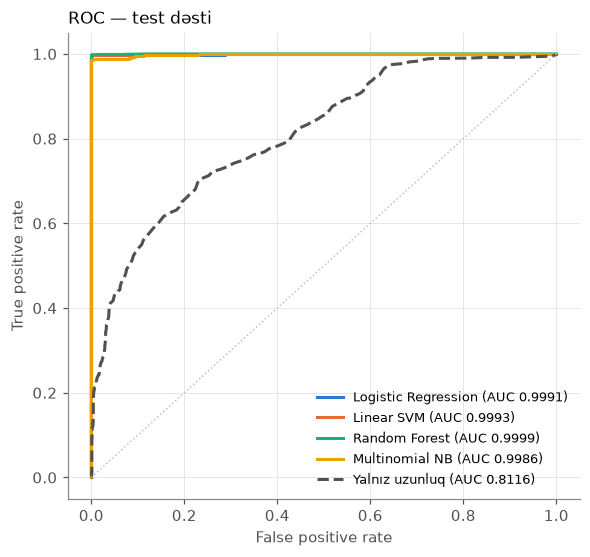

In [8]:
ROC_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
fig, ax = plt.subplots(figsize=(6, 5.5))
for (name, pipe), c in zip(pipelines.items(), ROC_COLORS):
    fpr, tpr, _ = roc_curve(y_test, score(pipe, X_test))
    auc = res.loc[res.model == name, "roc_auc"].iloc[0]
    ax.plot(fpr, tpr, color=c, linewidth=2, label=f"{name} (AUC {auc:.4f})")
fpr, tpr, _ = roc_curve(y_test, score(length_model, X_test))
auc = res.loc[res.model == "Length-only LR", "roc_auc"].iloc[0]
ax.plot(fpr, tpr, color="#52514e", linewidth=2, linestyle="--", label=f"Yalnız uzunluq (AUC {auc:.4f})")
ax.plot([0, 1], [0, 1], color="#c3c2b7", linewidth=1, linestyle=":")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC — test dəsti", loc="left", fontsize=11)
ax.legend(frameon=False, loc="lower right", fontsize=8.5)
save_fig(fig, "02_v2_roc_curves.png")
plt.show()

## 5. Ən yaxşı modelin confusion matrix-i və səhvləri

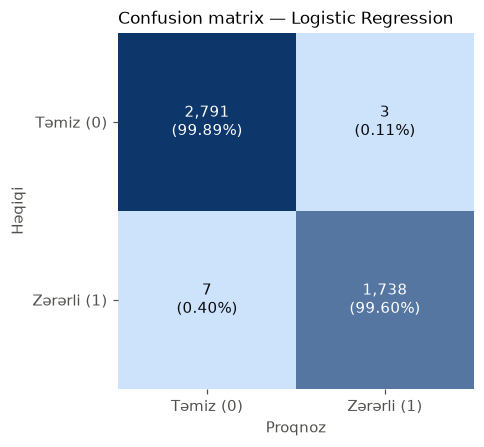

In [9]:
pred = best_model.predict(X_test)
cm = confusion_matrix(y_test, pred, labels=[0, 1])
cmap = LinearSegmentedColormap.from_list("blue_seq", ["#cde2fb", "#0d366b"])

fig, ax = plt.subplots(figsize=(4.8, 4.2))
ax.imshow(cm, cmap=cmap)
ax.grid(False)
for i in range(2):
    for j in range(2):
        val = cm[i, j]
        dark = val > cm.max() / 2
        ax.text(j, i, f"{val:,}\n({val / cm[i].sum() * 100:.2f}%)", ha="center", va="center",
                fontsize=10, color="white" if dark else "#0b0b0b")
ax.set_xticks([0, 1], [NAMES[0], NAMES[1]])
ax.set_yticks([0, 1], [NAMES[0], NAMES[1]])
ax.set_xlabel("Proqnoz")
ax.set_ylabel("Həqiqi")
ax.set_title(f"Confusion matrix — {best_name}", loc="left", fontsize=11)
for s in ax.spines.values():
    s.set_visible(False)
save_fig(fig, "02_v2_confusion_matrix_lr.png")
plt.show()

Səhv təsnif olunmuş nümunələr: **false positive** (təmiz, amma zərərli sayılıb) və **false negative**
(zərərli, amma buraxılıb), hər birindən ən çoxu 15. Ehtimal/skor ilə birlikdə göstərilir və
`results/02_misclassified.csv` faylına yazılır.

In [10]:
test_out = test[["Query", "Label"]].copy()
test_out["pred"] = pred
test_out["score"] = score(best_model, X_test)
test_out["length"] = test_out["Query"].str.len()

fp_rows = test_out[(test_out.Label == 0) & (test_out.pred == 1)].sort_values("score", ascending=False).head(15)
fn_rows = test_out[(test_out.Label == 1) & (test_out.pred == 0)].sort_values("score").head(15)
pd.concat([fp_rows.assign(error="FP"), fn_rows.assign(error="FN")]).to_csv(
    RES_DIR / "02_v2_misclassified.csv", index=False)

for title, rows in (("FALSE POSITIVE (təmiz → zərərli)", fp_rows), ("FALSE NEGATIVE (zərərli → təmiz)", fn_rows)):
    print(f"===== {title}: {len(rows)} göstərilir =====")
    for _, r in rows.iterrows():
        print(f"  skor={r.score:+.3f}  len={r.length:4d}  {r.Query[:160]!r}")
    print()

===== FALSE POSITIVE (təmiz → zərərli): 3 göstərilir =====
  skor=+0.996  len=  73  'SELECT * FROM Users WHERE Name  = "" or "" = "" AND Pass  = "" or "" = ""'
  skor=+0.546  len=   7  'sandler'
  skor=+0.511  len=   8  'ntpadmin'

===== FALSE NEGATIVE (zərərli → təmiz): 7 göstərilir =====
  skor=+0.000  len=   1  'a'
  skor=+0.001  len=   2  'os'
  skor=+0.001  len=   5  'PRINT'
  skor=+0.006  len=   8  'truncate'
  skor=+0.006  len=   1  '!'
  skor=+0.126  len=   3  'UEv'
  skor=+0.263  len=   4  "1\\'1"

